In [1]:
import random

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 

import warnings
warnings.filterwarnings("ignore")


In [2]:
data = sns.load_dataset('diamonds')
df = data

In [3]:
df.cut = pd.Categorical(df.cut)
df['cut'] = df.cut.cat.codes
df.color = pd.Categorical(df.color)
df['color'] = df.color.cat.codes
df.clarity = pd.Categorical(df.clarity)
df['clarity'] = df.clarity.cat.codes
df = df.sample(frac=1)
df

,carat,cut,color,clarity,depth,table,price,x,y,z
26503,1.70,3,3,5,60.9,60.0,16123,7.71,7.68,4.69
22966,1.01,2,0,7,61.5,57.0,11015,6.43,6.48,3.97
20577,1.00,3,1,7,62.7,60.0,8888,6.32,6.34,3.97
9694,0.32,1,0,2,63.3,57.0,589,4.36,4.39,2.77
32386,0.42,4,2,5,60.1,61.0,790,4.84,4.88,2.92
...,...,...,...,...,...,...,...,...,...,...
15794,1.71,2,6,2,62.8,57.0,6320,7.58,7.55,4.75
38171,0.34,3,3,1,62.3,59.0,1014,4.46,4.49,2.79
19709,0.41,2,5,5,61.4,54.0,625,4.81,4.83,2.96
7140,1.03,1,0,3,57.6,58.0,4177,6.60,6.67,3.82


In [4]:
train = df[:int(df.shape[0] * 0.7) ]
validation = df[int(df.shape[0] * 0.7):int(df.shape[0] * 0.85)]
test = df[int(df.shape[0] * 0.85):]
validation

,carat,cut,color,clarity,depth,table,price,x,y,z
39553,0.32,2,3,6,60.8,56.0,1080,4.44,4.37,2.68
37325,0.36,2,4,1,60.6,56.0,980,4.64,4.66,2.82
1884,0.90,1,3,2,63.7,56.0,3074,6.10,6.06,3.87
4588,0.76,4,3,7,62.1,56.0,3655,5.81,5.85,3.63
16948,1.01,4,2,5,62.3,59.0,6770,6.37,6.41,3.98
...,...,...,...,...,...,...,...,...,...,...
30642,0.41,0,5,4,65.3,58.0,735,4.62,4.66,3.03
3357,0.92,1,5,2,63.3,58.0,3382,6.14,6.18,3.90
15901,1.07,4,3,5,60.5,56.0,6355,6.64,6.71,4.04
24546,2.02,3,6,5,61.1,58.0,12832,8.04,8.10,4.93


In [5]:
for i in df.columns:
  print(i, ' - ', df[i].isna().sum())

carat  -  0
cut  -  0
color  -  0
clarity  -  0
depth  -  0
table  -  0
price  -  0
x  -  0
y  -  0
z  -  0


In [6]:
mean_val = train.mean(axis=0)
std_val = train.std(axis=0)
columns = ['carat', 'cut', 'color', 'clarity', 'depth', 'table',
'price', 'x', 'y', 'z']


In [7]:
def normalization(set, columns, mean_s, std_s): 
    for column in columns:
        mean = mean_s[column] 
        std = std_s[column] 
        temp = []
        for x in set[column]:
            t = (x - mean) / std
            temp.append(t)
        set[column] = temp

normalization(train, columns, mean_val, std_val) 
normalization(validation, columns, mean_val, std_val) 
normalization(test, columns, mean_val, std_val)


In [8]:
columns1 = ['carat', 'cut', 'color', 'depth', 'table',
'price', 'x', 'y', 'z']

In [9]:
from sklearn import preprocessing
X_train = train[columns1].values
y_train = train['clarity'].values
X_test = test[columns1].values
y_test = test['clarity'].values

X_validation = validation[columns1].values
y_validation = validation['clarity'].values

label_encoder = preprocessing.LabelEncoder()
y_train = label_encoder.fit_transform(y_train)
y_test = label_encoder.fit_transform(y_test)
y_validation = label_encoder.fit_transform(y_validation)


In [10]:
from sklearn import preprocessing
from sklearn import tree
from sklearn.decomposition import PCA

Depth 3, training dataset, SCORE: 0.5244098380917068


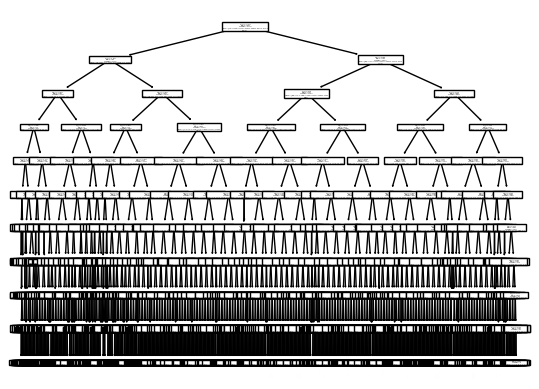

In [11]:
def desicion_tree(depth, x, y):
    clf = tree.DecisionTreeClassifier(max_depth=depth)
    clf = clf.fit(x, y)
    tree.plot_tree(clf) 
    return clf


data = desicion_tree(10, X_train, y_train)
print('Depth 3, training dataset, SCORE:', data.score(X_test, y_test))